# Experiment 9 — Decision Trees and Random Forest (Iris Dataset)

**Covers:** Full decision tree, restricted decision tree, tree plot, Random Forest, OOB score, evaluation, confusion matrices, ROC curves, feature importance, permutation importance, effect of tree count and CSV export.

**Dataset:** **Iris** – `Iris.csv` from Kaggle ([uciml/iris](https://www.kaggle.com/datasets/uciml/iris)), 150 flowers, columns `Id, SepalLengthCm, SepalWidthCm, PetalLengthCm, PetalWidthCm, Species`.

**Data file:** keep `Iris.csv` in the **same folder as this notebook** (or replace the file name with its full path, e.g. `pd.read_csv(r"C:\Users\Lab\Desktop\Iris.csv")`).

**Remember:** Split → Three models → Metrics → ROC → Tree plot → OOB → Feature importance → Tree count → Compare.

**Why Versicolor vs Virginica?** The lab manual asks for binary classification. Setosa is perfectly separable from the other two species, so every model would score 100%; the two overlapping species give a meaningful comparison.

## Import libraries and load the data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_validate
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report, roc_curve)

df = pd.read_csv("Iris.csv")

## 1. Same data as Experiment 8

In [2]:
# Binary classification: Versicolor (0) vs Virginica (1)
cols = ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm"]
data = df[df["Species"] != "Iris-setosa"]

X = data[cols]
y = (data["Species"] == "Iris-virginica").astype(int)

print("Class mapping: 0 = Versicolor, 1 = Virginica")
print(y.value_counts())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train:", len(X_train), "Test:", len(X_test))

Class mapping: 0 = Versicolor, 1 = Virginica
Species
0    50
1    50
Name: count, dtype: int64
Train: 80 Test: 20


## 2. Models (full tree, small tree, random forest)


 Full Tree


              precision    recall  f1-score   support

           0       0.75      0.90      0.82        10
           1       0.88      0.70      0.78        10

    accuracy                           0.80        20
   macro avg       0.81      0.80      0.80        20
weighted avg       0.81      0.80      0.80        20



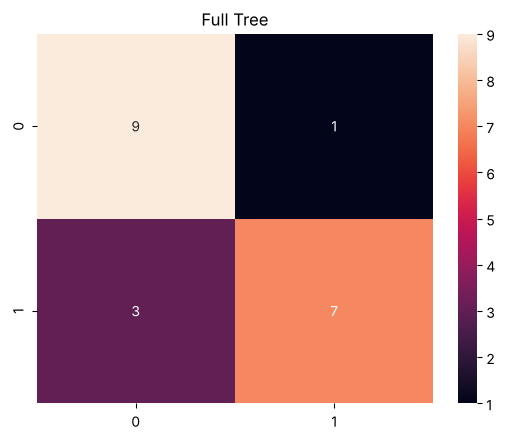


 Small Tree
              precision    recall  f1-score   support

           0       0.75      0.90      0.82        10
           1       0.88      0.70      0.78        10

    accuracy                           0.80        20
   macro avg       0.81      0.80      0.80        20
weighted avg       0.81      0.80      0.80        20



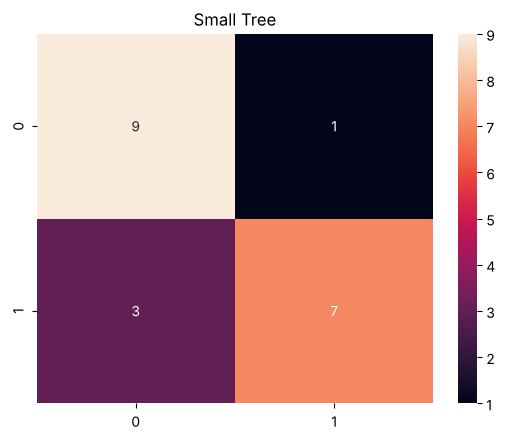


 Random Forest
              precision    recall  f1-score   support

           0       0.75      0.90      0.82        10
           1       0.88      0.70      0.78        10

    accuracy                           0.80        20
   macro avg       0.81      0.80      0.80        20
weighted avg       0.81      0.80      0.80        20



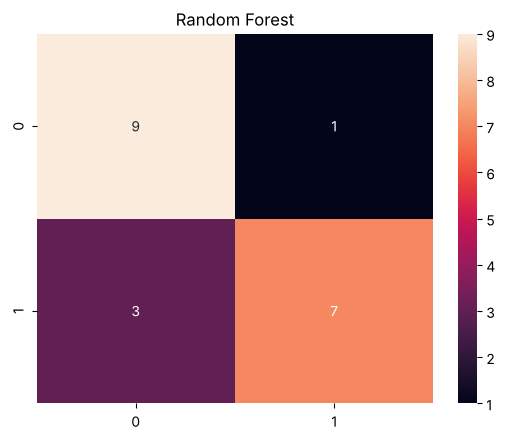

In [3]:
models = {
    "Full Tree": DecisionTreeClassifier(random_state=42),
    "Small Tree": DecisionTreeClassifier(
        max_depth=5, min_samples_split=10,
        min_samples_leaf=5, random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, oob_score=True, random_state=42, n_jobs=-1
    )
}

results = []
roc = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]

    results.append([
        name,
        accuracy_score(y_train, model.predict(X_train)),
        accuracy_score(y_test, pred),
        precision_score(y_test, pred),
        recall_score(y_test, pred),
        f1_score(y_test, pred),
        roc_auc_score(y_test, prob)
    ])

    print("\n", name)
    print(classification_report(y_test, pred))

    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d")
    plt.title(name)
    plt.show()

    fpr, tpr, _ = roc_curve(y_test, prob)
    roc[name] = (fpr, tpr)

## 3. ROC curves

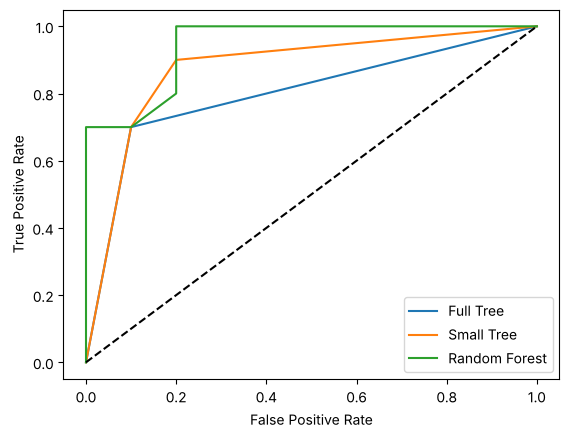

In [4]:
for name, (fpr, tpr) in roc.items():
    plt.plot(fpr, tpr, label=name)
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

## 4. Tree details and plot

Full Tree Depth: 3 Leaves: 4
Small Tree Depth: 2 Leaves: 3


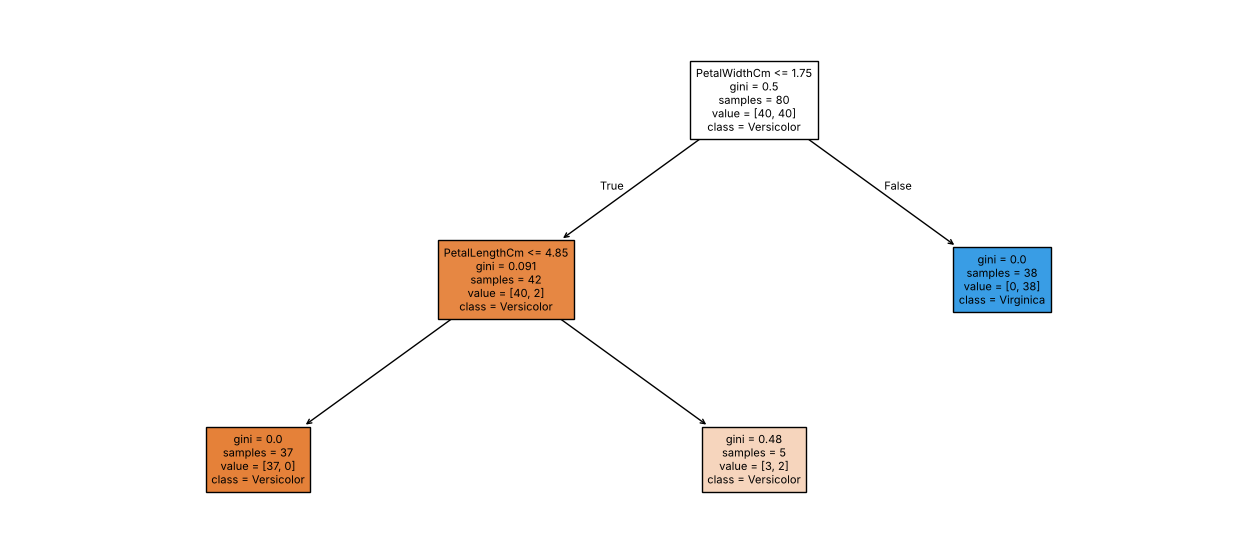

In [5]:
for name in ["Full Tree", "Small Tree"]:
    tree = models[name]
    print(name, "Depth:", tree.get_depth(), "Leaves:", tree.get_n_leaves())

plt.figure(figsize=(16, 7))
plot_tree(models["Small Tree"], feature_names=cols,
          class_names=["Versicolor", "Virginica"],
          max_depth=3, filled=True, fontsize=8)
plt.show()

## 5. Random Forest OOB score
Out-of-bag score = accuracy on the training rows each tree did not see.

In [6]:
rf = models["Random Forest"]
print("OOB Score:", rf.oob_score_)

OOB Score: 0.9625


## 6. Feature importance

                   Tree    Forest  Permutation  Permutation SD
SepalLengthCm  0.000000  0.098005       -0.020        0.024495
SepalWidthCm   0.033333  0.014594        0.000        0.000000
PetalLengthCm  0.061905  0.412584        0.055        0.047170
PetalWidthCm   0.904762  0.474817        0.170        0.092736


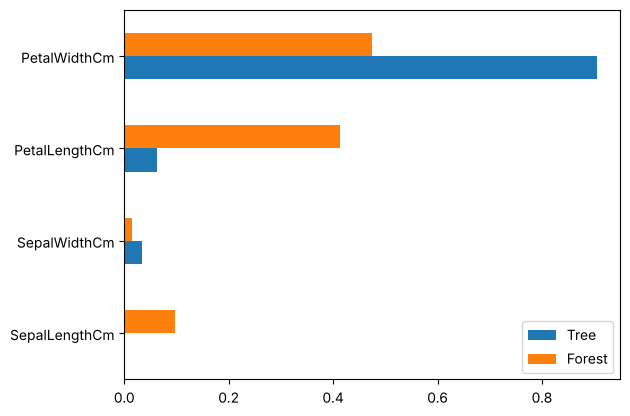

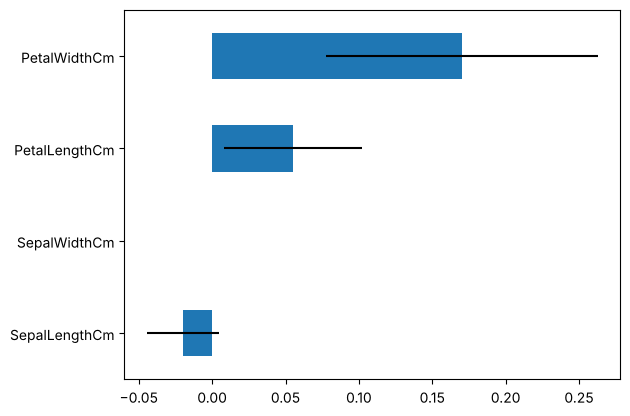

In [7]:
perm = permutation_importance(
    rf, X_test, y_test, n_repeats=10, random_state=42
)

importance = pd.DataFrame({
    "Tree": models["Full Tree"].feature_importances_,
    "Forest": rf.feature_importances_,
    "Permutation": perm.importances_mean,
    "Permutation SD": perm.importances_std
}, index=cols)

print(importance)

importance[["Tree", "Forest"]].plot(kind="barh")
plt.show()

importance["Permutation"].plot(
    kind="barh", xerr=importance["Permutation SD"]
)
plt.show()

## 7. Effect of number of trees (5-fold CV)

   Trees  Accuracy        F1       AUC
0     10    0.9625  0.963137  0.993750
1     25    0.9625  0.963137  0.996875
2     50    0.9625  0.963137  0.996875
3    100    0.9625  0.963137  0.996875
4    200    0.9625  0.963137  0.996875


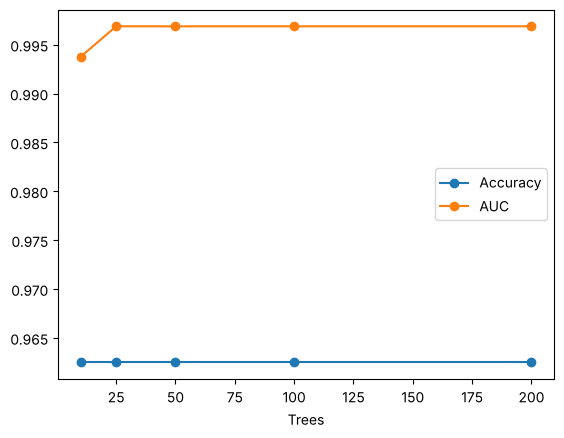

In [8]:
rows = []
for n in [10, 25, 50, 100, 200]:
    model = RandomForestClassifier(n_estimators=n, random_state=42, n_jobs=-1)
    cv = cross_validate(model, X_train, y_train, cv=5,
                        scoring=["accuracy", "f1", "roc_auc"])
    rows.append([n, cv["test_accuracy"].mean(),
                 cv["test_f1"].mean(), cv["test_roc_auc"].mean()])

tree_results = pd.DataFrame(
    rows, columns=["Trees", "Accuracy", "F1", "AUC"]
)
print(tree_results)

tree_results.plot(x="Trees", y=["Accuracy", "AUC"], marker="o")
plt.show()

## 8. Comparison and save

               Train Accuracy  Accuracy  Precision  Recall        F1    AUC
Model                                                                      
Full Tree               1.000       0.8      0.875     0.7  0.777778  0.800
Small Tree              0.975       0.8      0.875     0.7  0.777778  0.875
Random Forest           1.000       0.8      0.875     0.7  0.777778  0.945


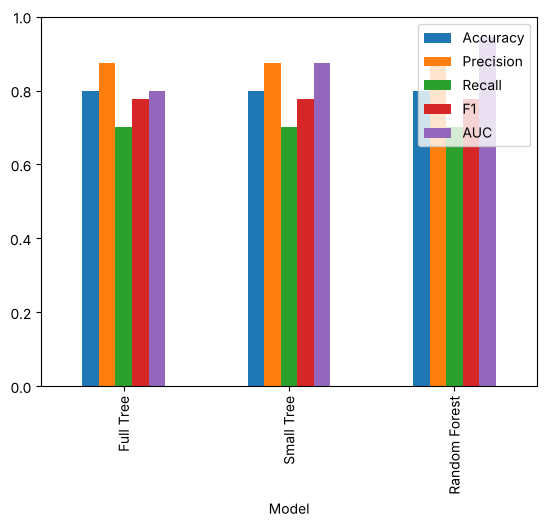

Saved tree_results.csv, feature_importance.csv, tree_count.csv


In [9]:
result = pd.DataFrame(results, columns=[
    "Model", "Train Accuracy", "Accuracy",
    "Precision", "Recall", "F1", "AUC"
]).set_index("Model")

print(result)
result.drop(columns="Train Accuracy").plot(kind="bar", ylim=(0, 1))
plt.show()

result.to_csv("tree_results.csv")
importance.to_csv("feature_importance.csv")
tree_results.to_csv("tree_count.csv", index=False)
print("Saved tree_results.csv, feature_importance.csv, tree_count.csv")

## Result / Conclusion
- Task: Versicolor vs Virginica. The full tree is tiny (depth 3, 4 leaves) and the small tree has depth 2, 3 leaves.
- All three models get the same test accuracy (0.80 – 4 mistakes out of 20), but the **Random Forest has the best AUC (0.945)** and an OOB score of 0.9625.
- `PetalWidthCm` is the most important feature (90% in the single tree, 47% in the forest, highest permutation importance), followed by `PetalLengthCm`.
- CV accuracy stays at 0.9625 for every forest size, so 10 trees are already enough for this small dataset.